In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

In [2]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/AllInOne_2022/Res_RR_lxy.coffea"

sig_histo = util.load(f_sig) [0]

Selected sample: 100 0.2 100
counts= [[8.3800e+02 2.2200e+02 8.0000e+00 0.0000e+00 0.0000e+00]
 [2.5350e+03 4.5500e+02 7.0000e+00 0.0000e+00 0.0000e+00]
 [1.0017e+04 1.9440e+03 2.7000e+01 2.0000e+00 0.0000e+00]
 [7.7350e+03 3.6120e+03 1.0500e+02 3.0000e+00 0.0000e+00]]
edges_pt= [ 0.  5. 10. 20. 30.]
edges_vxy= [ 0.  1.  5. 10. 15. 20.]


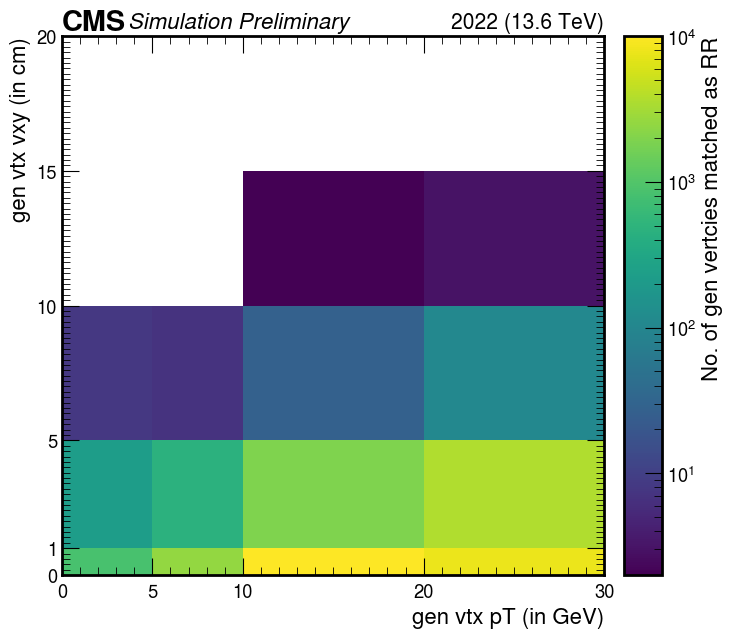

In [3]:
# Select one sample here for numerator and denominator.
m1 = 100
delta = 0.2
ctau = 100

fig, ax = plt.subplots(figsize=(7,7))

#Numerator: No. of gen vertices matched as RR

# Plot settings
plot_dict = {
    'variable':'genvtx_pt_vxy',
    'cut': 'cut1',
    'year': 2022
}

style_2d_dict = {
    'fig': fig,
    'ax': ax,
    'xrebin': None,
    'yrebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]  
    'ylim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': False, 
    'doLogx': False,
    'doLogz': True,
    'xlabel': "gen vtx pT (in GeV)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': "gen vtx vxy (in cm)",   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'zlabel': "No. of gen vertcies matched as RR",   
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'ptvslxy.png'
}

# Extract only the selected sample, with no loop or sum over samples.
h = ptools.plot_signal_2D(sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
counts = np.asarray(h[0], dtype=float)
edges_pt = np.asarray(h[1], dtype=float)
edges_vxy = np.asarray(h[2], dtype=float)
print("Selected sample:", m1, delta, ctau)
print("counts=", counts)
print("edges_pt=", edges_pt)
print("edges_vxy=", edges_vxy)


Selected sample: 100 0.2 100
counts_den= [[ 12547.  28947.  16984.   8543.   4690.]
 [ 36107.  78338.  43331.  20664.  10983.]
 [ 87611. 181875.  94427.  44824.  23904.]
 [ 39667. 109902.  73556.  39966.  22785.]]
edges_pt_den= [ 0.  5. 10. 20. 30.]
edges_vxy_den= [ 0.  1.  5. 10. 15. 20.]


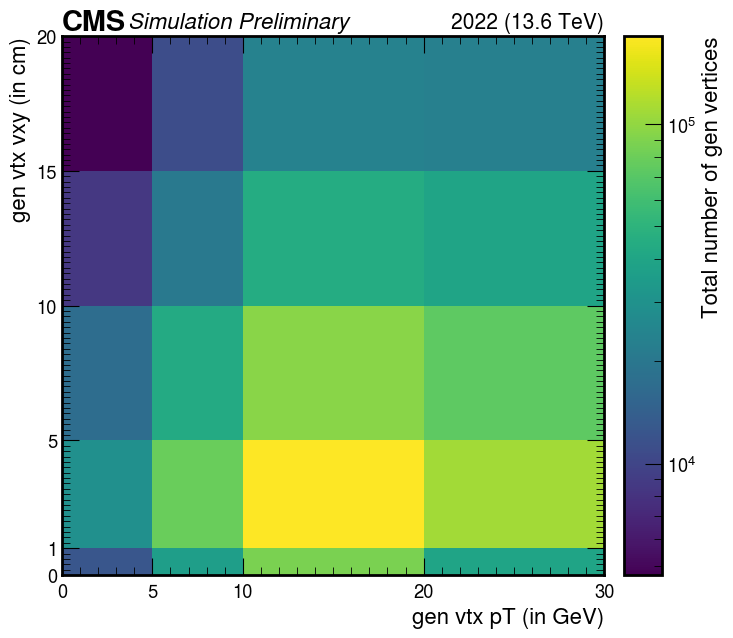

In [4]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'genvtx_pt_vxy_den',
    'cut': 'cut1',
    'year': 2022
}

style_2d_dict = {
    'fig': fig,
    'ax': ax,
    'xrebin': None,
    'yrebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]  
    'ylim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': False, 
    'doLogx': False,
    'doLogz': True,
    'xlabel': "gen vtx pT (in GeV)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': "gen vtx vxy (in cm)",   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'zlabel': "Total number of gen vertices",   
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'ptvslxy.png'
}

# Extract only the selected sample, with no loop or sum over samples.
h_den = ptools.plot_signal_2D(sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
counts_den = np.asarray(h_den[0], dtype=float)
edges_pt_den = np.asarray(h_den[1], dtype=float)
edges_vxy_den = np.asarray(h_den[2], dtype=float)
print("Selected sample:", m1, delta, ctau)
print("counts_den=", counts_den)
print("edges_pt_den=", edges_pt_den)
print("edges_vxy_den=", edges_vxy_den)


In [5]:
assert counts.shape == counts_den.shape, "Histogram shapes differ."
assert np.array_equal(edges_pt, edges_pt_den), "pT bin edges differ."
assert np.array_equal(edges_vxy, edges_vxy_den), "vxy bin edges differ."


def eff_determine_unc(n, d):
    eff = np.divide(n, d)
    unc = hist.intervals.ratio_uncertainty(n, d, 'efficiency')
    return eff, unc



efficiency_rr, unc_rr = eff_determine_unc(counts, counts_den)
print ("efficiency_rr=", efficiency_rr)
print ("unc_rr=", unc_rr)

efficiency_rr= [[6.67888738e-02 7.66918852e-03 4.71031559e-04 0.00000000e+00
  0.00000000e+00]
 [7.02079929e-02 5.80816462e-03 1.61547160e-04 0.00000000e+00
  0.00000000e+00]
 [1.14334958e-01 1.06886598e-02 2.85935167e-04 4.46189541e-05
  0.00000000e+00]
 [1.94998361e-01 3.28656439e-02 1.42748382e-03 7.50638042e-05
  0.00000000e+00]]
unc_rr= [[[2.23359818e-03 5.12614473e-04 1.62983611e-04 0.00000000e+00
   0.00000000e+00]
  [1.34642999e-03 2.71471776e-04 5.95737421e-05 0.00000000e+00
   0.00000000e+00]
  [1.07637181e-03 2.41162066e-04 5.46802266e-05 2.88196559e-05
   0.00000000e+00]
  [1.99414676e-03 5.38060515e-04 1.39005142e-04 4.08520708e-05
   0.00000000e+00]]

 [[2.30388445e-03 5.47777438e-04 2.32204083e-04 2.15477384e-04
   3.92464894e-04]
  [1.37048144e-03 2.84385545e-04 8.70003497e-05 8.90892197e-05
   1.67610612e-04]
  [1.08522253e-03 2.46604176e-04 6.62855038e-05 5.88462243e-05
   7.70143387e-05]
  [2.00962208e-03 5.46633338e-04 1.53224619e-04 7.30113039e-05
   8.07964569e-05

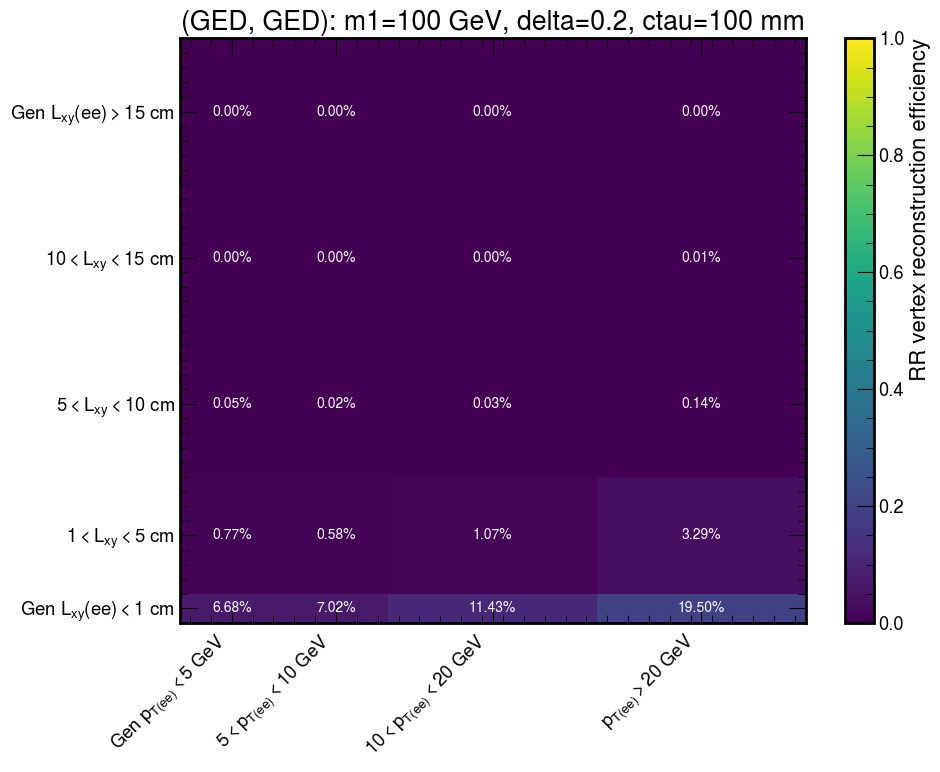

In [6]:
# Calculate the 2D efficiency safely
efficiency_rr = np.divide(
    counts,
    counts_den,
    out=np.full_like(counts, np.nan, dtype=float),
    where=(counts_den > 0)
)

efficiency_to_plot = efficiency_rr.T

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    edges_pt,
    edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("RR vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (edges_pt[:-1] + edges_pt[1:])
vxy_centers = 0.5 * (edges_vxy[:-1] + edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            # f"{efficiency:.2f}",
            f"{100 * efficiency:.2f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Create x-axis labels automatically from the actual pT edges
x_labels = []

for index in range(len(pt_centers)):
    low_edge = edges_pt[index]
    high_edge = edges_pt[index + 1]

    if index == 0:
        label = rf"Gen $p_{{\mathrm{{T}}(ee)}} < {high_edge:g}$ GeV"
    elif index == len(pt_centers) - 1:
        label = rf"$p_{{\mathrm{{T}}(ee)}} > {low_edge:g}$ GeV"
    else:
        label = (
            rf"${low_edge:g} < p_{{\mathrm{{T}}(ee)}}"
            rf" < {high_edge:g}$ GeV"
        )

    x_labels.append(label)

# Create y-axis labels automatically from the actual vxy edges
y_labels = []

for index in range(len(vxy_centers)):
    low_edge = edges_vxy[index]
    high_edge = edges_vxy[index + 1]

    if index == 0:
        label = rf"Gen $L_{{xy}}(ee) < {high_edge:g}$ cm"
    elif index == len(vxy_centers) - 1:
        label = rf"Gen $L_{{xy}}(ee) > {low_edge:g}$ cm"
    else:
        label = rf"${low_edge:g} < L_{{xy}} < {high_edge:g}$ cm"

    y_labels.append(label)

# Set custom tick positions and labels
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"(GED, GED): m1={m1} GeV, delta={delta}, ctau={ctau} mm")

plt.tight_layout()
plt.show()

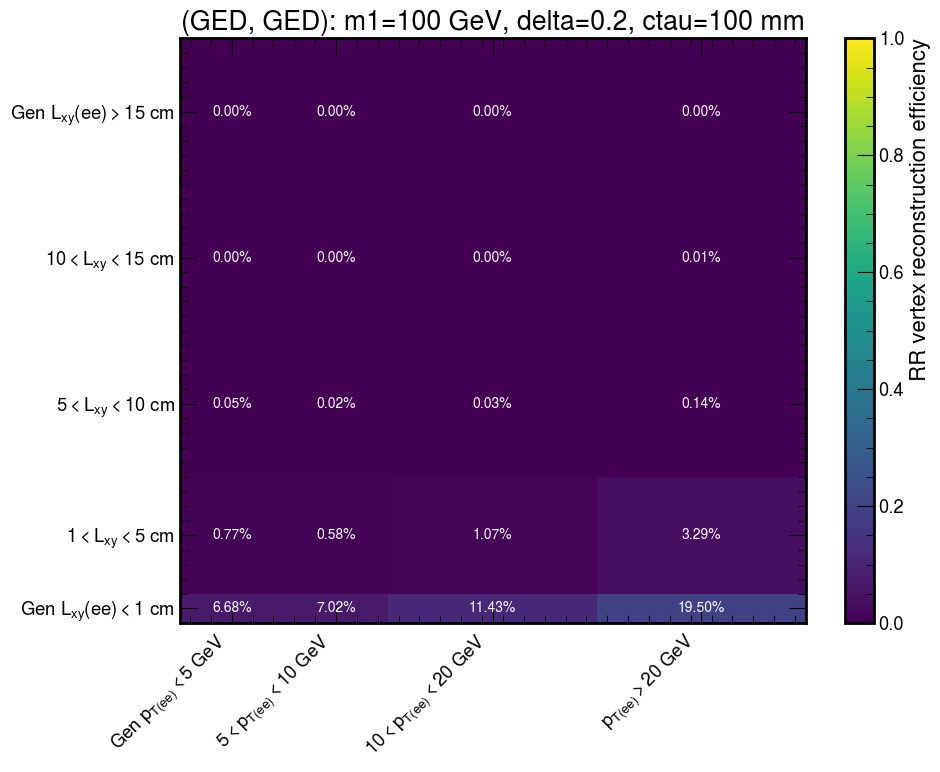

In [7]:
# Calculate the 2D efficiency safely
efficiency_rr = np.divide(
    counts,
    counts_den,
    out=np.full_like(counts, np.nan, dtype=float),
    where=(counts_den > 0)
)

efficiency_to_plot = efficiency_rr.T

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    edges_pt,
    edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("RR vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (edges_pt[:-1] + edges_pt[1:])
vxy_centers = 0.5 * (edges_vxy[:-1] + edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            # f"{efficiency:.2f}",
            f"{100 * efficiency:.2f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Create x-axis labels automatically from the actual pT edges
x_labels = []

for index in range(len(pt_centers)):
    low_edge = edges_pt[index]
    high_edge = edges_pt[index + 1]

    if index == 0:
        label = rf"Gen $p_{{\mathrm{{T}}(ee)}} < {high_edge:g}$ GeV"
    elif index == len(pt_centers) - 1:
        label = rf"$p_{{\mathrm{{T}}(ee)}} > {low_edge:g}$ GeV"
    else:
        label = (
            rf"${low_edge:g} < p_{{\mathrm{{T}}(ee)}}"
            rf" < {high_edge:g}$ GeV"
        )

    x_labels.append(label)

# Create y-axis labels automatically from the actual vxy edges
y_labels = []

for index in range(len(vxy_centers)):
    low_edge = edges_vxy[index]
    high_edge = edges_vxy[index + 1]

    if index == 0:
        label = rf"Gen $L_{{xy}}(ee) < {high_edge:g}$ cm"
    elif index == len(vxy_centers) - 1:
        label = rf"Gen $L_{{xy}}(ee) > {low_edge:g}$ cm"
    else:
        label = rf"${low_edge:g} < L_{{xy}} < {high_edge:g}$ cm"

    y_labels.append(label)

# Set custom tick positions and labels
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"(GED, GED): m1={m1} GeV, delta={delta}, ctau={ctau} mm")

plt.tight_layout()
plt.show()